# Loading Data 


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import SGDRegressor , LinearRegression
from sklearn.preprocessing import PolynomialFeatures

import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(42)
torch.manual_seed(42)

plt.style.use('dark_background') 

print("All libraries loaded successfully!")
print(f"NumPy version: {np.__version__}")
print(f"PyTorch version: {torch.__version__}")

All libraries loaded successfully!
NumPy version: 2.3.5
PyTorch version: 2.14.1+cpu


In [3]:
california= fetch_california_housing()
x = california.data 
y = california.target 

feature_names = california.feature_names
print(california.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [22]:
# Need to see first 5 rows 

for i in range(5):
    print(f"House {i}")
    for j,name in enumerate(feature_names):
        print(f"  {name} {x[i,j]:.2f}")
    print()        

House 0
  MedInc 8.33
  HouseAge 41.00
  AveRooms 6.98
  AveBedrms 1.02
  Population 322.00
  AveOccup 2.56
  Latitude 37.88
  Longitude -122.23

House 1
  MedInc 8.30
  HouseAge 21.00
  AveRooms 6.24
  AveBedrms 0.97
  Population 2401.00
  AveOccup 2.11
  Latitude 37.86
  Longitude -122.22

House 2
  MedInc 7.26
  HouseAge 52.00
  AveRooms 8.29
  AveBedrms 1.07
  Population 496.00
  AveOccup 2.80
  Latitude 37.85
  Longitude -122.24

House 3
  MedInc 5.64
  HouseAge 52.00
  AveRooms 5.82
  AveBedrms 1.07
  Population 558.00
  AveOccup 2.55
  Latitude 37.85
  Longitude -122.25

House 4
  MedInc 3.85
  HouseAge 52.00
  AveRooms 6.28
  AveBedrms 1.08
  Population 565.00
  AveOccup 2.18
  Latitude 37.85
  Longitude -122.25



In [36]:
print("Feature Statistics:\n")
print(f"{'Feature':<15} {'Mean':<12} {'Std':<12} {'Min':<12} {'Max':<12}")
print(59*"=")

for i , name in enumerate(feature_names):
    print(f"{name:<15}{np.mean(x[:,i]):<12.2f}{np.std(x[:,i]):<12.2f}{np.min(x[:,i]):<12.2f}{np.max(x[:,i]):<12.2f}")

print(f"\n{'Target (Price)':<15} {np.mean(y):<12.2f} {np.std(y):<12.2f} {np.min(y):<12.2f} {np.max(y):<12.2f}")    

Feature Statistics:

Feature         Mean         Std          Min          Max         
MedInc         3.87        1.90        0.50        15.00       
HouseAge       28.64       12.59       1.00        52.00       
AveRooms       5.43        2.47        0.85        141.91      
AveBedrms      1.10        0.47        0.33        34.07       
Population     1425.48     1132.43     3.00        35682.00    
AveOccup       3.07        10.39       0.69        1243.33     
Latitude       35.63       2.14        32.54       41.95       
Longitude      -119.57     2.00        -124.35     -114.31     

Target (Price)  2.07         1.15         0.15         5.00        


# Exploratory Data Analysis (EDA)
## Part 2: Correlation Analysis


In [59]:
correlation = []
for i in range(x.shape[1]):
    corr = np.corrcoef(x[:,i],y)[0,1]
    correlation.append(corr)

sorted_indices = np.argsort(np.abs(correlation))[::-1]
print("Features ranked by correlation with Price:\n")
print(f"{'Rank':<6} {'Feature':<15} {'Correlation':<12}")
print("="*35)

for rank , idx in enumerate(sorted_indices,1):
    print(f"{rank:<6}{feature_names[idx]:<15}{correlation[idx]:>+11.3f}")
    

Features ranked by correlation with Price:

Rank   Feature         Correlation 
1     MedInc              +0.688
2     AveRooms            +0.152
3     Latitude            -0.144
4     HouseAge            +0.106
5     AveBedrms           -0.047
6     Longitude           -0.046
7     Population          -0.025
8     AveOccup            -0.024


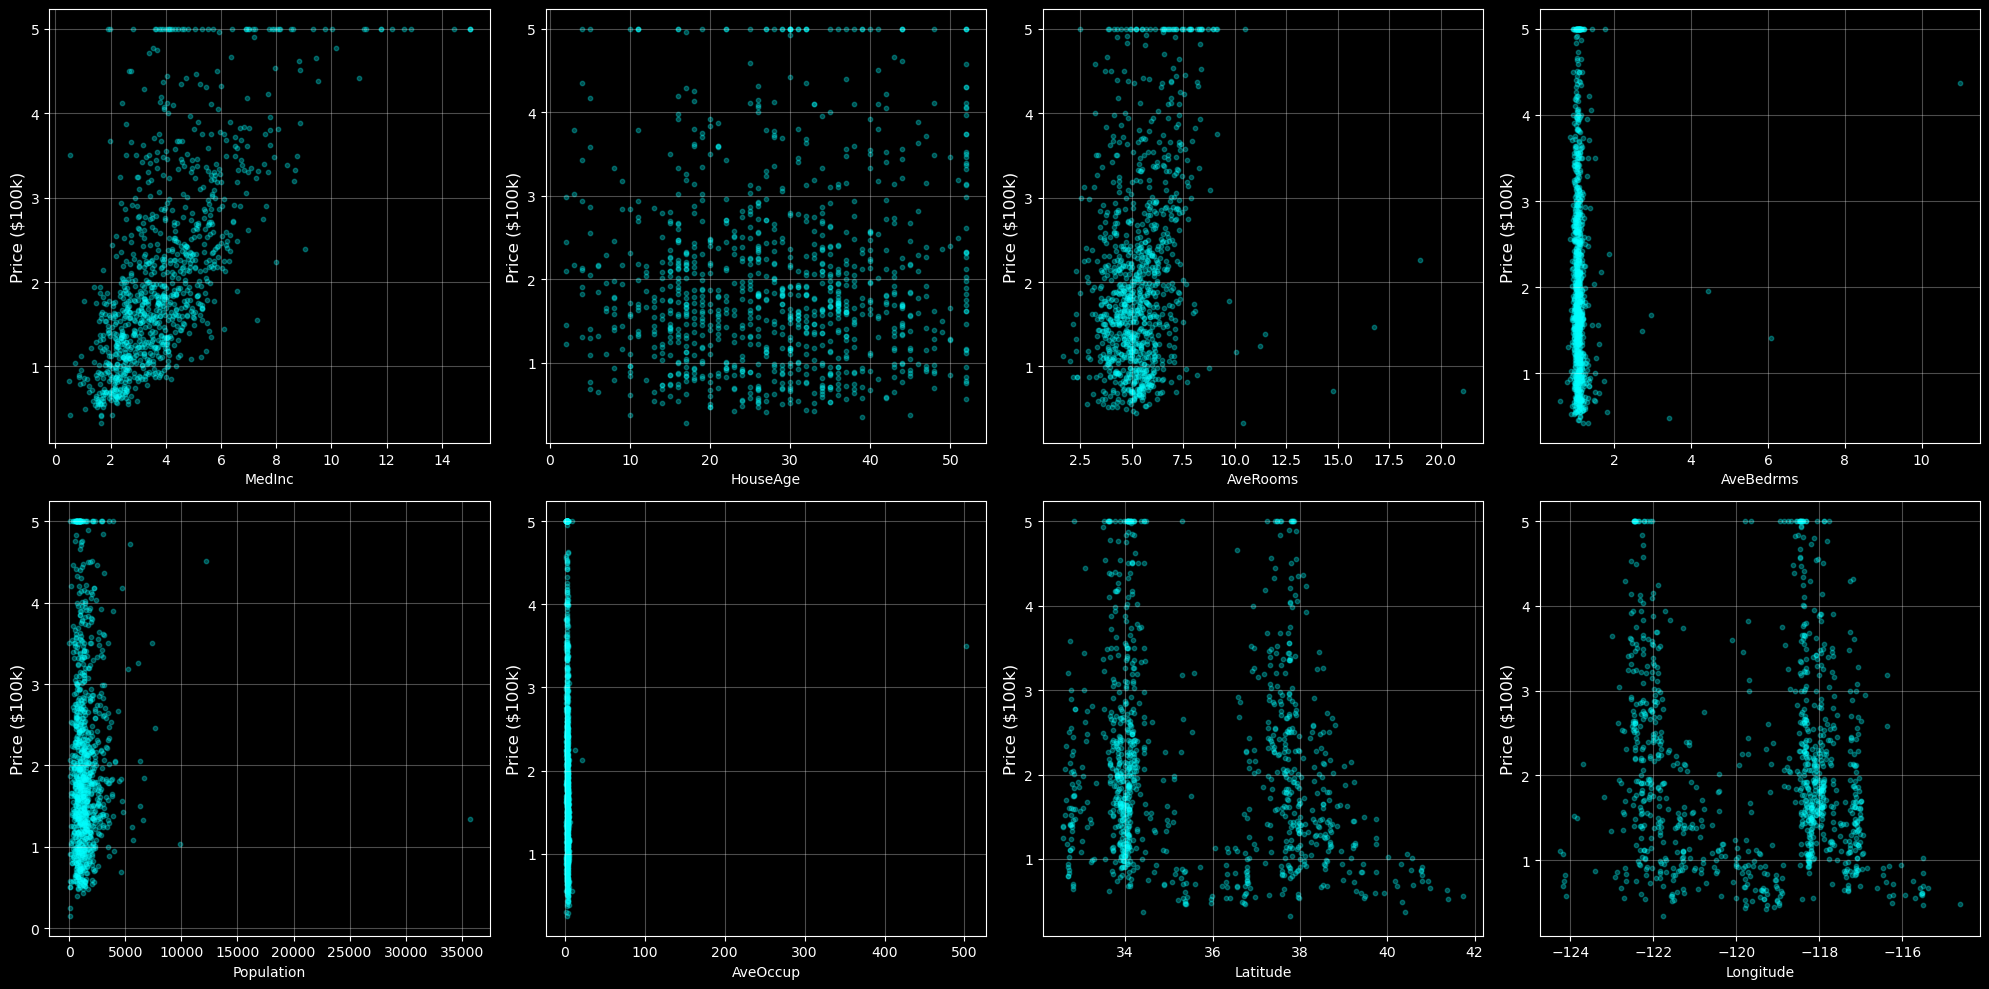

In [77]:
# Visualize all features vs target
fig , axes = plt.subplots(2,4,figsize = (20,10))
axes = axes.flatten()

for i , (ax,name) in enumerate(zip(axes,feature_names)):
    indices = np.random.choice(x.shape[0],1000,replace=False)
    ax.scatter(x[indices,i],y[indices],alpha=0.3 , s=10,c='cyan')
    ax.set_xlabel(name)
    ax.set_ylabel('Price ($100k)', fontsize=12)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

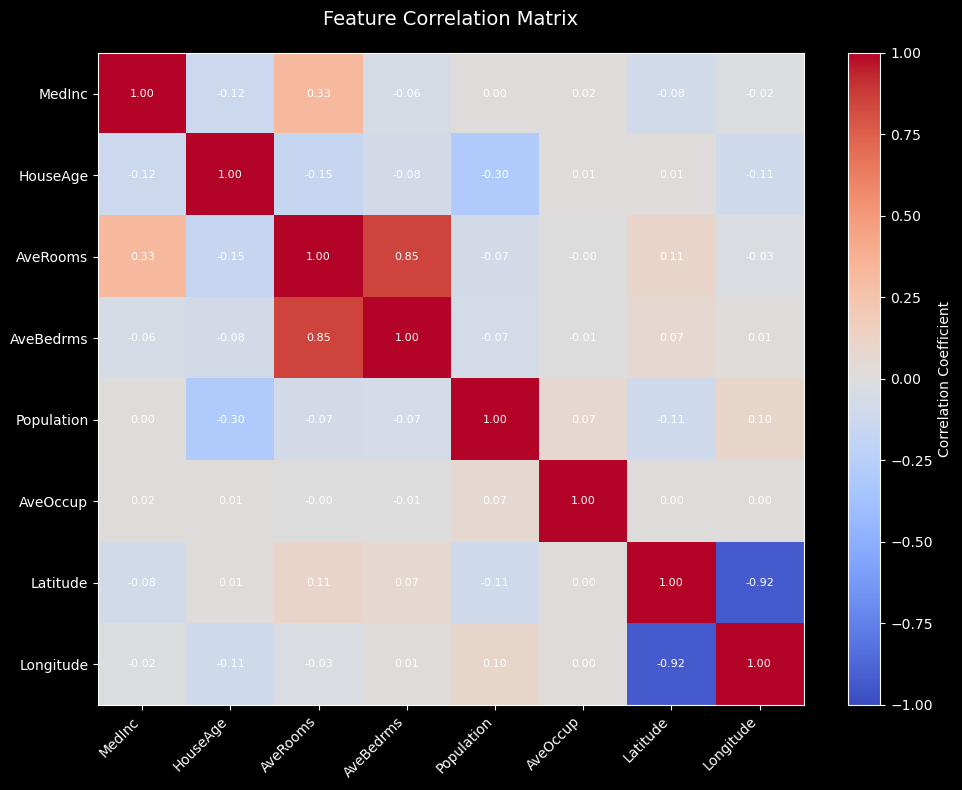

In [78]:
# Correlation matrix heatmap
# Calculate correlation between all features
correlation_matrix = np.corrcoef(x.T)

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='Correlation Coefficient')
plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha='right')
plt.yticks(range(len(feature_names)), feature_names)
plt.title('Feature Correlation Matrix', fontsize=14, pad=20)

# Add correlation values
for i in range(len(feature_names)):
    for j in range(len(feature_names)):
        plt.text(j, i, f'{correlation_matrix[i, j]:.2f}',
                ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.show()


# Part 3: Linear Regression

In [47]:
x_medinc = x[:,0]
y_price = y
print(f"Training samples: {len(x_medinc):,}")
print(f"Feature: {feature_names[0]}")
print(f"Target: Median house value")

Training samples: 20,640
Feature: MedInc
Target: Median house value


In [53]:
# Initialize parameters
np.random.seed(42)
w = np.random.rand()
b = np.random.rand()

eta= 0.01 
epochs = 1000

n = len(x_medinc)
cost_history = []


In [54]:
for epoch in range(epochs):
    yhat = w * x_medinc+b
    w = w - eta*np.mean((yhat-y)*x_medinc) 
    b = b - eta * np.mean(yhat-y)
    cost = 0.5 * np.mean((yhat-y)**2)
    cost_history.append(cost)

    if (epoch+1) % 100 == 0 or epoch == 0 :
        print(f"Epoch {epoch+1:4d}: Cost = {cost:.4f}, w = {w:.4f}, b = {b:.4f}")

print(f"\nTraining complete!")
print(f"Final w: {w:.4f}")
print(f"Final b: {b:.4f}")
print(f"Final cost (MSE): {cost_history[-1]:.4f}")         

Epoch    1: Cost = 0.4090, w = 0.3633, b = 0.9474
Epoch  100: Cost = 0.3665, w = 0.3328, b = 0.8555
Epoch  200: Cost = 0.3616, w = 0.3473, b = 0.7868
Epoch  300: Cost = 0.3581, w = 0.3593, b = 0.7297
Epoch  400: Cost = 0.3558, w = 0.3693, b = 0.6823
Epoch  500: Cost = 0.3542, w = 0.3775, b = 0.6430
Epoch  600: Cost = 0.3530, w = 0.3844, b = 0.6104
Epoch  700: Cost = 0.3523, w = 0.3901, b = 0.5833
Epoch  800: Cost = 0.3517, w = 0.3948, b = 0.5608
Epoch  900: Cost = 0.3514, w = 0.3987, b = 0.5421
Epoch 1000: Cost = 0.3511, w = 0.4020, b = 0.5266

Training complete!
Final w: 0.4020
Final b: 0.5266
Final cost (MSE): 0.3511


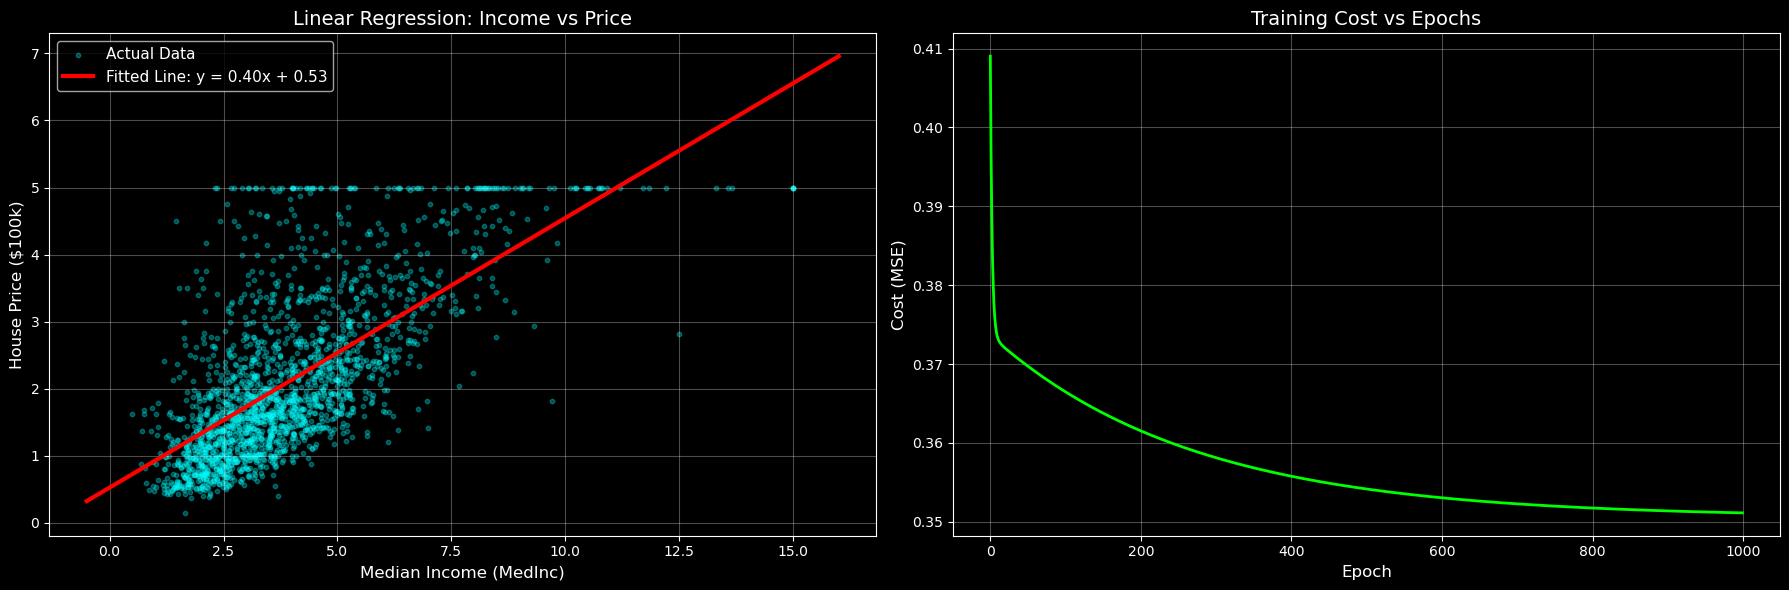


Notice how the cost decreases smoothly - this is gradient descent working!
The red line shows our model's predictions.


In [77]:
# Visualize the results

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
ax1=axes[0]
indices = np.random.choice(n,2000,replace=False)
ax1.scatter(x_medinc[indices],y[indices],c='cyan',alpha =0.3,s=10,label='Actual Data')

xvals = np.linspace(x_medinc.min()-1,x_medinc.max()+1,1000)
yvals = w*xvals + b 

ax1.plot(xvals, yvals, 'r-', linewidth=3, label=f'Fitted Line: y = {w:.2f}x + {b:.2f}')
ax1.set_xlabel('Median Income (MedInc)', fontsize=12)
ax1.set_ylabel('House Price ($100k)', fontsize=12)
ax1.set_title('Linear Regression: Income vs Price', fontsize=14)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)



ax2 = axes[1]
ax2 = axes[1]
ax2.plot(cost_history, 'lime', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Cost (MSE)', fontsize=12)
ax2.set_title('Training Cost vs Epochs', fontsize=14)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nNotice how the cost decreases smoothly - this is gradient descent working!")
print("The red line shows our model's predictions.")

# Test 


In [80]:
test_incomes = np.array([2.0, 4.0, 6.0, 8.0])
test_predictions = w * test_incomes + b 

for income , pred in zip(test_incomes,test_predictions):
    print(f"Median Income = {income:.1f} → Predicted Price = ${pred*100000:,.0f}")

Median Income = 2.0 → Predicted Price = $133,063
Median Income = 4.0 → Predicted Price = $213,464
Median Income = 6.0 → Predicted Price = $293,865
Median Income = 8.0 → Predicted Price = $374,267
